## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("hf_token_rp")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [47]:
import os
import random
import json
import time
import math
import zipfile
import shutil

# Hugging Face dataset
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# You can use any of the 4 train files or all the files for pre-training the legal model
TRAIN_FILE0 = "Phase_1_Pretraining/Train/train_supreme_court.json"
TRAIN_FILE1 = "Phase_1_Pretraining/Train/train_high_courts.json"
TRAIN_FILE2 = "Phase_1_Pretraining/Train/train_acts.json"
TRAIN_FILE3 = "Phase_1_Pretraining/Train/train_tribunals.json"

TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# Training configuration
TRAIN_TOKENS = 200_000_000
VAL_TOKENS = 5_000_000
TRAIN_BLOCK_SIZE = 2048
EPOCHS = 3
SEED = 42
random.seed(SEED)
MODEL_CONTEXT_LENGTH = 2048
N_EMBD = 700
N_LAYER = 10
N_HEAD = 8

# Generation
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.75
TOP_P = 0.95

# Kaggle output
OUTPUT_DIR = "/kaggle/working/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR,
    "legal-mamba-ssm-final"
)
PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "prediction.json"
)
SUBMISSION_ZIP = os.path.join(
    OUTPUT_DIR,
    "submission.zip"
)
LOSS_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "training_validation_loss.png"
)
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)
print("Configuration loaded.")

# ------------------------------------------------------------
# Run-mode switches
# ------------------------------------------------------------
# False: load the saved BPE tokenizer used for every submission (recommended).
# True : retrain the BPE tokenizer from the corpus (slow, pure Python).
TRAIN_NEW_TOKENIZER = False
TOKENIZER_INPUT_PATH = "/kaggle/input/datasets/mohdsarimali/folder/legal_bpe.json"

# Optional pre-tokenized corpus (train/val token arrays). If it is not attached,
# the mixed corpus is built and tokenized in this notebook and cached in OUTPUT_DIR.
TOKENIZED_CACHE_INPUT = "/kaggle/input/datasets/mohdsarimali/folder/tokenized_data.npz"

# Full-corpus token statistics (used for the report). Very slow; off by default.
COUNT_CORPUS_TOKENS = False

# Resume a Trainer checkpoint, e.g. "/kaggle/input/datasets/mohdsarimali/chkpt8k"
# (the run used for the submission). None trains from random initialization.
RESUME_FROM_CHECKPOINT = None


Configuration loaded.


## 4. Download Training Data From Hugging Face

In [ ]:
from huggingface_hub import hf_hub_download

# Download all four training files
TRAIN_FILES = {
    "supreme_court": hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=TRAIN_FILE0,
        repo_type="dataset"
    ),
    "high_courts": hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=TRAIN_FILE1,
        repo_type="dataset"
    ),
    "acts": hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=TRAIN_FILE2,
        repo_type="dataset"
    ),
    "tribunals": hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=TRAIN_FILE3,
        repo_type="dataset"
    )
}

for source, path in TRAIN_FILES.items():
    print(f"{source}: {path}")

## 5. Load Tokenizer

In [36]:
# from transformers import AutoTokenizer

# tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
# tokenizer.pad_token = tokenizer.eos_token
# print("Vocabulary size:", len(tokenizer))

#BPE tokenizer

def train_tokenizer(train_text, vocab_size):
    tokenizer = ByteLevelBPE(vocab_size=vocab_size)
    tokenizer.train([train_text])
    return tokenizer

# ============================================================
# QUESTION 5 — OPTIMIZED BYTE-LEVEL BPE
# ============================================================

import json
from collections import Counter, defaultdict
from tqdm.auto import tqdm


BPE_SPECIALS = [
    "<pad>",
    "<unk>",
    "<s>",
    "</s>"
]

# End-of-word marker.
# UTF-8 bytes are integers 0..255, so 256 cannot collide.
EOW = 256


class ByteLevelBPE:
    """
    Deterministic byte-level BPE tokenizer.

    - Initial units are UTF-8 bytes.
    - EOW marks the end of each word.
    - Case is preserved.
    - BPE never crosses word boundaries.
    - Ties are broken lexicographically.
    - Four special tokens are fixed at the beginning.
    """

    def __init__(self, vocab_size=5000):

        self.vocab_size = vocab_size
        self.merge_ranks = {}
        self.specials = list(BPE_SPECIALS)

        # List of learned merges.
        #
        # Each element is:
        #     (left_symbol, right_symbol)
        #
        self.merges = []

        # Vocabulary.
        self.itos = []
        self.stoi = {}

        # Internal merge rules.
        #
        # (left, right) -> merged_symbol
        #
        self.merge_rules = {}

        # Final representations of words seen during training.
        self.word_cache = {}
        self.token_to_symbol = {}

    # --------------------------------------------------------
    # Convert a byte/symbol tuple into a deterministic string
    # --------------------------------------------------------
    @staticmethod
    def string_to_symbol(token):
        # Standalone end-of-word marker
        if token == "</w>":
            return (EOW,)
    
        # Merged symbol ending with EOW
        if token.endswith("</w>>"):
            hex_part = token[3:-5]
            byte_part = tuple(
                int(hex_part[i:i+2], 16)
                for i in range(0, len(hex_part), 2)
            )
            return byte_part + (EOW,)
    
        # Ordinary byte or merged byte symbol
        hex_part = token[3:-1]
        return tuple(
            int(hex_part[i:i+2], 16)
            for i in range(0, len(hex_part), 2)
        )
    @staticmethod
    def symbol_to_string(symbol):

        # EOW is always the last symbol when present.
        if symbol and symbol[-1] == EOW:

            byte_part = symbol[:-1]

            if len(byte_part) == 0:
                return "</w>"

            hex_part = "".join(
                f"{b:02x}"
                for b in byte_part
            )

            return f"<0x{hex_part}</w>>"

        hex_part = "".join(
            f"{b:02x}"
            for b in symbol
        )

        return f"<0x{hex_part}>"
    def _build_merge_ranks(self):
        self.merge_ranks = {
            pair: rank
            for rank, pair in enumerate(self.merge_rules)
        }
    # --------------------------------------------------------
    # Deterministic ordering key for symbols
    # --------------------------------------------------------

    @staticmethod
    def symbol_key(symbol):
        return tuple(symbol)

    # --------------------------------------------------------
    # Convert a word into initial UTF-8 byte symbols
    # --------------------------------------------------------

    @staticmethod
    def word_to_symbols(word):

        byte_values = list(
            word.encode("utf-8")
        )

        symbols = [
            (b,)
            for b in byte_values
        ]

        # Explicit word boundary.
        symbols.append((EOW,))

        return symbols

    # --------------------------------------------------------
    # Count all pairs once initially
    # --------------------------------------------------------

    def _initial_pair_counts(
        self,
        word_symbols,
        word_counts
    ):

        pair_counts = Counter()

        # pair_words tells us which words contain a pair.
        pair_words = defaultdict(set)

        for word, symbols in word_symbols.items():

            freq = word_counts[word]

            for i in range(len(symbols) - 1):

                pair = (
                    symbols[i],
                    symbols[i + 1]
                )

                pair_counts[pair] += freq
                pair_words[pair].add(word)

        return pair_counts, pair_words

    # --------------------------------------------------------
    # Merge one pair in one word
    # --------------------------------------------------------

    @staticmethod
    def _merge_word(symbols, pair):

        left, right = pair

        new_symbol = left + right

        result = []

        i = 0

        while i < len(symbols):

            if (
                i + 1 < len(symbols)
                and symbols[i] == left
                and symbols[i + 1] == right
            ):

                result.append(new_symbol)

                i += 2

            else:

                result.append(symbols[i])

                i += 1

        return result

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    def train(self, texts):

        print("=" * 70)
        print("Training BYTE-LEVEL BPE")
        print("=" * 70)

        # ----------------------------------------------------
        # Count unique words.
        # ----------------------------------------------------

        word_counts = Counter()

        for text in texts:
            if not isinstance(text, str):
                continue

            for word in text.split():

                word_counts[word] += 1

        print(
            f"Unique words: {len(word_counts):,}"
        )

        # ----------------------------------------------------
        # Initial representation of each word.
        # ----------------------------------------------------

        word_symbols = {
            word: self.word_to_symbols(word)
            for word in word_counts
        }

        # ----------------------------------------------------
        # Initial vocabulary symbols.
        # ----------------------------------------------------

        initial_symbols = [
            (b,)
            for b in range(256)
        ]

        initial_symbols.append((EOW,))

        # Four specials + initial byte symbols.
        current_vocab_size = (
            len(BPE_SPECIALS)
            + len(initial_symbols)
        )

        print(
            f"Initial vocabulary size: "
            f"{current_vocab_size:,}"
        )

        if current_vocab_size > self.vocab_size:

            raise ValueError(
                "Initial byte vocabulary already exceeds "
                "the requested vocabulary size."
            )

        # ----------------------------------------------------
        # Count pairs once.
        # ----------------------------------------------------

        pair_counts, pair_words = \
            self._initial_pair_counts(
                word_symbols,
                word_counts
            )

        # ----------------------------------------------------
        # Main BPE loop.
        # ----------------------------------------------------

        merge_no = 0

        while current_vocab_size < self.vocab_size:

            if not pair_counts:
                break

            # Ignore pairs occurring only once.
            valid_pairs = [
                pair
                for pair, count in pair_counts.items()
                if count > 1
            ]

            if not valid_pairs:
                print(
                    "No pair occurs more than once. "
                    "Stopping early."
                )
                break

            # Highest frequency first.
            # Lexicographically smallest pair on ties.
            best_pair = min(
                valid_pairs,
                key=lambda pair: (
                    -pair_counts[pair],
                    self.symbol_key(pair[0]),
                    self.symbol_key(pair[1])
                )
            )

            best_count = pair_counts[best_pair]

            left, right = best_pair
            new_symbol = left + right

            # ------------------------------------------------
            # Record merge.
            # ------------------------------------------------

            self.merge_rules[best_pair] = new_symbol

            self.merges.append(
                (
                    self.symbol_to_string(left),
                    self.symbol_to_string(right)
                )
            )

            # ------------------------------------------------
            # Words affected by this merge.
            # ------------------------------------------------

            affected_words = list(
                pair_words.get(best_pair, set())
            )

            # Remove the selected pair's old contribution.
            del pair_counts[best_pair]

            pair_words.pop(
                best_pair,
                None
            )

            # ------------------------------------------------
            # Update each affected word.
            # ------------------------------------------------

            for word in affected_words:

                old_symbols = word_symbols[word]

                old_pairs = []

                for i in range(
                    len(old_symbols) - 1
                ):

                    old_pairs.append(
                        (
                            old_symbols[i],
                            old_symbols[i + 1]
                        )
                    )

                # Remove old pair contributions.
                freq = word_counts[word]

                for pair in old_pairs:

                    pair_counts[pair] -= freq

                    if pair_counts[pair] <= 0:
                        pair_counts.pop(
                            pair,
                            None
                        )

                    if pair in pair_words:
                        pair_words[pair].discard(word)

                        if not pair_words[pair]:
                            pair_words.pop(
                                pair,
                                None
                            )

                # Perform merge.
                new_symbols = self._merge_word(
                    old_symbols,
                    best_pair
                )

                word_symbols[word] = new_symbols

                # Add new pair contributions.
                new_pairs = []

                for i in range(
                    len(new_symbols) - 1
                ):

                    new_pairs.append(
                        (
                            new_symbols[i],
                            new_symbols[i + 1]
                        )
                    )

                for pair in new_pairs:

                    pair_counts[pair] += freq
                    pair_words[pair].add(word)

            current_vocab_size += 1
            merge_no += 1

            if merge_no % 250 == 0:

                print(
                    f"Merges: {merge_no:4d} | "
                    f"Vocab: {current_vocab_size:5d} | "
                    f"Best pair frequency: {best_count:,}"
                )

        # ----------------------------------------------------
        # Construct final vocabulary.
        #
        # First:
        #   <pad>, <unk>, <s>, </s>
        #
        # Then initial symbols.
        #
        # Then symbols introduced by merges in merge order.
        # ----------------------------------------------------

        merged_symbols = list(
            self.merge_rules.values()
        )

        self.itos = (
            list(BPE_SPECIALS)
            +
            [
                self.symbol_to_string(s)
                for s in initial_symbols
            ]
            +
            [
                self.symbol_to_string(s)
                for s in merged_symbols
            ]
        )

        self.token_to_symbol = {}

        for symbol in initial_symbols:
            token = self.symbol_to_string(symbol)
            self.token_to_symbol[token] = symbol

        for symbol in merged_symbols:
            token = self.symbol_to_string(symbol)
            self.token_to_symbol[token] = symbol

        # Remove duplicates while preserving order.
        final_itos = []
        seen = set()

        for token in self.itos:

            if token not in seen:

                seen.add(token)
                final_itos.append(token)

        self.itos = final_itos[
            :self.vocab_size
        ]

        self.stoi = {
            token: i
            for i, token in enumerate(self.itos)
        }

        # Save representations of training words.
        self.word_cache = word_symbols

        print(
            "\nTraining complete."
        )

        print(
            f"Final vocabulary size: "
            f"{len(self.itos):,}"
        )

        print(
            f"Number of merges: "
            f"{len(self.merges):,}"
        )
        self._build_merge_ranks()
        return self

    # --------------------------------------------------------
    # Tokenize a word
    # --------------------------------------------------------

    def tokenize_word(self, word):
        # Use cached representation for training words.
        if word in self.word_cache:
            symbols = self.word_cache[word]
        else:
            symbols = self.word_to_symbols(word)
    
            while len(symbols) > 1:
                # Find adjacent pairs that have learned merges.
                candidates = [
                    (self.merge_ranks[(symbols[i], symbols[i + 1])], i)
                    for i in range(len(symbols) - 1)
                    if (symbols[i], symbols[i + 1]) in self.merge_ranks
                ]
    
                if not candidates:
                    break
    
                # Apply the earliest learned merge.
                _, best_idx = min(candidates)
    
                pair = (symbols[best_idx], symbols[best_idx + 1])
                new_symbol = self.merge_rules[pair]
    
                # Merge all non-overlapping occurrences.
                symbols = self._merge_word(symbols, pair)
    
        return [
            self.symbol_to_string(symbol)
            for symbol in symbols
        ]

    # --------------------------------------------------------
    # Tokenize complete sentence
    # --------------------------------------------------------

    def tokenize(self, text):

        tokens = []

        for word in text.split():

            tokens.extend(
                self.tokenize_word(word)
            )

        return tokens

    def encode(self, text):
        tokens = self.tokenize(text)

        ids = []
        for token in tokens:
            if token in self.stoi:
                ids.append(self.stoi[token])
            else:
                # unknown token
                ids.append(self.stoi["<unk>"])

        return ids

    def decode(self, ids):
      byte_values = []

      for idx in ids:
          token = self.itos[idx]

          if token in BPE_SPECIALS:
              continue

          symbol = self.token_to_symbol[token]

          for b in symbol:
              if b == EOW:
                  byte_values.append(ord(" "))
              else:
                  byte_values.append(b)

      # Remove the final space
      if byte_values and byte_values[-1] == ord(" "):
          byte_values.pop()

      return bytes(byte_values).decode("utf-8",errors="ignore")

    @classmethod
    def load(cls, path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
    
        tokenizer = cls(vocab_size=data["vocab_size"])
        tokenizer.merges = data["merges"]
        tokenizer.itos = data["itos"]
        tokenizer.stoi = {
            token: i for i, token in enumerate(tokenizer.itos)
        }
    
        # Initial symbols
        initial_symbols = [(b,) for b in range(256)]
        initial_symbols.append((EOW,))
    
        tokenizer.token_to_symbol = {
            tokenizer.symbol_to_string(symbol): symbol
            for symbol in initial_symbols
        }
    
        # Reconstruct merge rules in training order
        for left_str, right_str in tokenizer.merges:
            left = tokenizer.string_to_symbol(left_str)
            right = tokenizer.string_to_symbol(right_str)
            merged = left + right
    
            tokenizer.merge_rules[(left, right)] = merged
            merged_str = tokenizer.symbol_to_string(merged)
            tokenizer.token_to_symbol[merged_str] = merged
        tokenizer._build_merge_ranks()  
        return tokenizer

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    def save(self, path):

        data = {
            "merges": self.merges,
            "itos": self.itos,
            "vocab_size": self.vocab_size
        }

        with open(
            path,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                data,
                f,
                ensure_ascii=False
            )

        print(
            f"Saved: {path}"
        )

# if __name__ == "__main__":
#     train_text = """
#     Harry went to Hogwarts.
#     Harry met Ron and Hermione.
#     Hogwarts was a magical school.
#     """

#     tokenizer = train_tokenizer(train_text, 5000)

#     print("Vocab size:", tokenizer.vocab_size)

#     text = "Harry went to Hogwarts."

#     ids = tokenizer.encode(text)
#     decoded = tokenizer.decode(ids)

#     print("Text:", text)
#     print("IDs:", ids)
#     print("Decoded:", decoded)
#     print("Match:", text == decoded)


In [ ]:
!pip install ijson
import os
import ijson

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

VOCAB_SIZE = 16000
MAX_CHARS_PER_SOURCE = 5_000_000

TOKENIZER_PATH = os.path.join(
    OUTPUT_DIR, "legal_bpe.json"
)


# ------------------------------------------------------------
# Extract text from a record
# ------------------------------------------------------------

def get_text(record):
    if isinstance(record, str):
        return record

    if isinstance(record, dict):
        for key in [
            "text", "content", "judgment",
            "document", "full_text", "body"
        ]:
            if isinstance(record.get(key), str):
                return record[key]

    raise ValueError(
        f"Unable to extract text. Record type: {type(record)}"
    )


# ------------------------------------------------------------
# Stream text from JSON files
# ------------------------------------------------------------

def iter_texts(file_path):
    with open(file_path, "rb") as f:
        for record in ijson.items(f, "item"):
            text = get_text(record)
            if text.strip():
                yield text


# ------------------------------------------------------------
# Create bounded training sample
# ------------------------------------------------------------

def all_documents():
    for source, path in TRAIN_FILES.items():
        print(f"Processing {source}...")

        total_chars = 0

        for text in iter_texts(path):
            remaining = MAX_CHARS_PER_SOURCE - total_chars

            if remaining <= 0:
                break

            text = text[:remaining]

            if text.strip():
                yield text
                total_chars += len(text)

        print(f"{source}: {total_chars:,} characters")


# ------------------------------------------------------------
# Train and save tokenizer
# ------------------------------------------------------------

if TRAIN_NEW_TOKENIZER:
    tokenizer = ByteLevelBPE(vocab_size=VOCAB_SIZE)
    tokenizer.train(all_documents())

    tokenizer.save(TOKENIZER_PATH)

    print(f"Tokenizer saved at: {TOKENIZER_PATH}")

In [37]:
# Load the tokenizer: the one trained above, or the saved tokenizer used for the submissions.
tokenizer = ByteLevelBPE.load(
    TOKENIZER_PATH if TRAIN_NEW_TOKENIZER else TOKENIZER_INPUT_PATH
)

print("Vocabulary size:", len(tokenizer.itos))
print("Number of merges:", len(tokenizer.merges))

# Special-token ids (needed by the corpus tokenization step below).
PAD_ID = tokenizer.stoi["<pad>"]   # 0
UNK_ID = tokenizer.stoi["<unk>"]   # 1
BOS_ID = tokenizer.stoi["<s>"]     # 2
EOS_ID = tokenizer.stoi["</s>"]    # 3


Vocabulary size: 16000
Number of merges: 15739


In [ ]:
import json
from tqdm.auto import tqdm
from pathlib import Path

# ------------------------------------------------------------
# Count tokens in one source
# ------------------------------------------------------------


def count_source_tokens(tokenizer, file_path):
    total_tokens = 0
    total_docs = 0
    total_chars = 0

    for text in tqdm(
        iter_texts(file_path),
        desc=Path(file_path).name
    ):
        ids = tokenizer.encode(text)

        total_tokens += len(ids)
        total_docs += 1
        total_chars += len(text)

        del ids

    return {
        "documents": total_docs,
        "characters": total_chars,
        "tokens": total_tokens,
    }


# ------------------------------------------------------------
# Count tokens in all sources
# ------------------------------------------------------------

def count_all_sources(tokenizer):
    results = {}

    for source, file_path in TRAIN_FILES.items():
        print(f"\nCounting {source}...")
        results[source] = count_source_tokens(
            tokenizer, file_path
        )

    return results


# ------------------------------------------------------------
# Print and save statistics
# ------------------------------------------------------------

def save_and_print_counts(results, output_path="token_counts.json"):
    total_tokens = sum(
        stats["tokens"] for stats in results.values()
    )

    print("\n" + "=" * 75)
    print(
        f"{'Source':<20}{'Documents':>15}"
        f"{'Characters':>18}{'Tokens':>18}"
    )
    print("=" * 75)

    for source, stats in results.items():
        print(
            f"{source:<20}"
            f"{stats['documents']:>15,}"
            f"{stats['characters']:>18,}"
            f"{stats['tokens']:>18,}"
        )

    print("=" * 75)
    print(f"{'TOTAL':<20}{'':>15}{'':>18}{total_tokens:>18,}")

    with open(output_path, "w") as f:
        json.dump(
            {
                "sources": results,
                "total_tokens": total_tokens,
            },
            f,
            indent=2,
        )

    print(f"\nStatistics saved to {output_path}")


# ------------------------------------------------------------
# Run
# ------------------------------------------------------------
tokenizer._build_merge_ranks()
if COUNT_CORPUS_TOKENS:
    results = count_all_sources(tokenizer)
    save_and_print_counts(results)
else:
    print("Skipped full-corpus token counting (COUNT_CORPUS_TOKENS=False).")

In [5]:
def run_tokenizer_checks(tokenizer):
    print("Vocabulary size:", len(tokenizer.itos))
    assert len(tokenizer.itos) == len(tokenizer.stoi)
    assert len(tokenizer.itos) <= tokenizer.vocab_size

    # Symbol serialization round trips
    symbols = [
        (97,),
        (97, 98),
        (97, 98, EOW),
        (EOW,),
        (240, 159, 152, 128, EOW),
    ]

    for symbol in symbols:
        encoded = tokenizer.symbol_to_string(symbol)
        decoded = tokenizer.string_to_symbol(encoded)
        assert decoded == symbol, (symbol, encoded, decoded)

    # Text round trips: your current tokenizer normalizes whitespace.
    tests = [
        "The Supreme Court held that the appeal is allowed.",
        "Section 302 of the Indian Penal Code.",
        "Article 14 and Article 21.",
        "A.B.C. v. State of X",
        "न्यायालय",
        "AnUnseenWord123",
    ]

    for text in tests:
        ids = tokenizer.encode(text)
        decoded = tokenizer.decode(ids)

        # Compare against the whitespace-normalized text.
        expected = " ".join(text.split())
        assert decoded == expected, (text, decoded, expected)

    # Save/load consistency
    tokenizer.save("tokenizer_check.json")
    loaded = ByteLevelBPE.load("tokenizer_check.json")

    for text in tests:
        assert tokenizer.encode(text) == loaded.encode(text)

    print("All checks passed.")


run_tokenizer_checks(tokenizer)

Vocabulary size: 16000
Saved: tokenizer_check.json
All checks passed.


## Mixing Strategy

In [ ]:

import random
from pathlib import Path
from tqdm.auto import tqdm


# ============================================================
# CORPUS MIXING CONFIGURATION
# Change only this dictionary to tune your data strategy.
# ============================================================

MIXING_STRATEGY = {
    "supreme_court": 1.00,
    "high_courts":    0.30,
    "acts":           1.00,
    "tribunals":      0.50,
}

RANDOM_SEED = 42


def mixed_legal_corpus(
    train_files,
    mixing_strategy=MIXING_STRATEGY,
    seed=RANDOM_SEED,
    show_progress=True,
):
    """
    Stream a mixed legal corpus using document-level sampling.

    Parameters
    ----------
    train_files : dict
        Maps source names to their input file paths.
    mixing_strategy : dict
        Sampling fraction for each source, from 0.0 to 1.0.
    seed : int
        Random seed for reproducibility.
    show_progress : bool
        Whether to show progress bars while reading sources.

    Yields
    ------
    str
        Selected documents in a randomized interleaving
        of the source datasets.

    Notes
    -----
    - Sampling is performed independently per document.
    - The selected token proportions are approximate.
    - Documents are not all loaded into memory.
    """

    rng = random.Random(seed)

    # Validate source names and sampling fractions.
    for source, fraction in mixing_strategy.items():
        if source not in train_files:
            raise ValueError(f"Unknown source: {source}")
        if not 0.0 <= fraction <= 1.0:
            raise ValueError(
                f"Invalid sampling fraction for {source}: {fraction}"
            )

    # Create a document stream for each source.
    source_streams = {}

    for source, fraction in mixing_strategy.items():
        if fraction == 0:
            continue

        file_path = train_files[source]

        def selected_documents(
            file_path=file_path,
            fraction=fraction,
            source=source,
        ):
            documents = iter_texts(file_path)

            if show_progress:
                documents = tqdm(
                    documents,
                    desc=f"Sampling {source}",
                )

            for text in documents:
                if not isinstance(text, str) or not text.strip():
                    continue

                # Keep or skip each document independently.
                if rng.random() < fraction:
                    yield text

        source_streams[source] = iter(selected_documents())

    # Randomly interleave the active source streams.
    active_sources = list(source_streams.keys())

    while active_sources:
        source = rng.choice(active_sources)

        try:
            yield next(source_streams[source])
        except StopIteration:
            active_sources.remove(source)

In [ ]:
import json

def save_mixed_corpus(
    output_path="mixed_legal_corpus.jsonl",
    train_files=TRAIN_FILES,
    mixing_strategy=MIXING_STRATEGY,
    seed=42,
):
    total_docs = 0
    total_chars = 0

    with open(output_path, "w", encoding="utf-8") as f:
        for text in mixed_legal_corpus(
            train_files=train_files,
            mixing_strategy=mixing_strategy,
            seed=seed,
        ):
            f.write(json.dumps(
                {"text": text},
                ensure_ascii=False
            ) + "\n")

            total_docs += 1
            total_chars += len(text)

    print(f"Documents saved: {total_docs:,}")
    print(f"Characters saved: {total_chars:,}")
    print(f"Output file: {output_path}")

    return {
        "documents": total_docs,
        "characters": total_chars,
        "output_path": output_path,
    }


WORKING_TOKEN_CACHE = os.path.join(OUTPUT_DIR, "tokenized_data.npz")
if os.path.exists(TOKENIZED_CACHE_INPUT) or os.path.exists(WORKING_TOKEN_CACHE):
    print("Tokenized cache found; mixed corpus not rebuilt.")
else:
    mixing_stats = save_mixed_corpus()

In [ ]:
# #load it


# import json

# CORPUS_PATH = "/kaggle/input/datasets/richierich6/corpus/combined_corpus.jsonl"

# # Inspect a few documents
# with open(CORPUS_PATH, "r", encoding="utf-8") as f:
#     for i, line in enumerate(f):
#         doc = json.loads(line)
#         text = doc["text"]

#         # Tokenize using your custom ByteLevelBPE tokenizer
#         token_ids = tokenizer.encode(text)

#         print(f"Document {i+1}")
#         print("Characters:", len(text))
#         print("Tokens:", len(token_ids))
#         print("Sample text:", text[:200])
#         print("First 20 token IDs:", token_ids[:20])
#         print("-" * 60)

#         if i == 2:
#             break
# print("Vocabulary size:", tokenizer.vocab_size)
# print("Special tokens:", tokenizer.specials)

# print("First 10 stoi entries:", list(tokenizer.stoi.items())[:10])

# print("Last 10 itos entries:")
# for idx, token in enumerate(
#     tokenizer.itos[-10:],
#     start=len(tokenizer.itos) - 10
# ):
#     print(idx, repr(token))

# # Check whether special token IDs exist
# print("BOS token ID:", getattr(tokenizer, "bos_token_id", None))
# print("EOS token ID:", getattr(tokenizer, "eos_token_id", None))
# print("PAD token ID:", getattr(tokenizer, "pad_token_id", None))

## 6. Create Train and Validation Tokens Set

In [5]:
import json
import random
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

# Corpus produced by save_mixed_corpus() above.
train_file_path = "mixed_legal_corpus.jsonl"

# Read the attached cache if present; otherwise build it once in OUTPUT_DIR (writable).
CACHE_PATH = (
    TOKENIZED_CACHE_INPUT
    if Path(TOKENIZED_CACHE_INPUT).exists()
    else os.path.join(OUTPUT_DIR, "tokenized_data.npz")
)

if Path(CACHE_PATH).exists():
    # Reuse previously tokenized data
    cached = np.load(CACHE_PATH)
    train_tokens = cached["train_tokens"].tolist()
    val_tokens = cached["val_tokens"].tolist()

    print("Loaded tokenized data from cache.")

else:
    train_tokens = []
    val_tokens = []
    rng = random.Random(SEED)

    with open(train_file_path, "r", encoding="utf-8") as f:
        for line in tqdm(f, desc="Tokenizing corpus"):
            if not line.strip():
                continue

            text = json.loads(line)["text"]
            tokens = tokenizer.encode(text)
            tokens.append(EOS_ID)

            # Split at document level
            if rng.random() < 0.05 and len(val_tokens) < VAL_TOKENS:
                remaining = VAL_TOKENS - len(val_tokens)
                val_tokens.extend(tokens[:remaining])

            elif len(train_tokens) < TRAIN_TOKENS:
                remaining = TRAIN_TOKENS - len(train_tokens)
                train_tokens.extend(tokens[:remaining])

            if (
                len(train_tokens) >= TRAIN_TOKENS
                and len(val_tokens) >= VAL_TOKENS
            ):
                break

    # Save tokens for future reuse
    np.savez(
        CACHE_PATH,
        train_tokens=np.array(train_tokens, dtype=np.int32),
        val_tokens=np.array(val_tokens, dtype=np.int32)
    )

    print("Tokenized data saved to cache.")

print(f"Train tokens: {len(train_tokens):,}")
print(f"Validation tokens: {len(val_tokens):,}")

Loaded tokenized data from cache.
Train tokens: 200,000,000
Validation tokens: 5,000,000


## 7. Create Token Blocks

In [6]:
def create_blocks(tokens, block_size):
    total_length = (len(tokens) // block_size) * block_size
    tokens = tokens[:total_length]
    return [tokens[i:i + block_size] for i in range(0, total_length, block_size)]

train_blocks = create_blocks(train_tokens, TRAIN_BLOCK_SIZE)
val_blocks = create_blocks(val_tokens, TRAIN_BLOCK_SIZE)

print("Training sequences:", len(train_blocks))
print("Validation sequences:", len(val_blocks))

Training sequences: 97656
Validation sequences: 2441


## 8. Create Datasets

In [7]:
from datasets import Dataset

train_dataset = Dataset.from_dict({"input_ids": train_blocks})
val_dataset = Dataset.from_dict({"input_ids": val_blocks})

print(train_dataset)
print(val_dataset)

Dataset({
    features: ['input_ids'],
    num_rows: 97656
})
Dataset({
    features: ['input_ids'],
    num_rows: 2441
})


In [ ]:
# import os

# input_file = "/kaggle/working/mixed_legal_corpus.jsonl"
# output_dir = "/kaggle/working/corpus_parts"

# os.makedirs(output_dir, exist_ok=True)

# max_size = 500 * 1024 * 1024  # 500 MB

# part = 0
# current_size = 0
# out = None

# with open(input_file, "rb") as f:
#     for line in f:
#         if out is None or current_size + len(line) > max_size:
#             if out is not None:
#                 out.close()

#             part_path = os.path.join(
#                 output_dir, f"corpus_{part:02d}.jsonl"
#             )
#             out = open(part_path, "wb")
#             print("Created:", part_path)

#             part += 1
#             current_size = 0

#         out.write(line)
#         current_size += len(line)

# if out is not None:
#     out.close()

In [ ]:
print("Train examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))

print("Train block length:", len(train_dataset[0]["input_ids"]))
print("Validation block length:", len(val_dataset[0]["input_ids"]))

print("First 20 tokens:", train_dataset[0]["input_ids"][:20])
print("EOS token ID:", EOS_ID)

print(
    "EOS count in first block:",
    train_dataset[0]["input_ids"].count(EOS_ID)
)

## 9. Define The Model

## Architecture 4 - Real Diagonal SSM / S4D-inspired LM


In [8]:
PAD_ID = tokenizer.stoi["<pad>"]   # 0
UNK_ID = tokenizer.stoi["<unk>"]   # 1
BOS_ID = tokenizer.stoi["<s>"]     # 2
EOS_ID = tokenizer.stoi["</s>"]    # 3

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
class SSMLM(nn.Module):
    def __init__(
        self,
        vocab_size,
        dim,
        n_layer,
        max_seq_len,
        state_dim=16,
        expand=3,
    ):
        super().__init__()

        self.vocab_size = vocab_size
        self.dim = dim
        self.n_layer = n_layer
        self.max_seq_len = max_seq_len

        self.embedding = nn.Embedding(
            vocab_size,
            dim
        )

        self.layers = nn.ModuleList([
            SSMBlock(
                dim=dim,
                state_dim=state_dim,
                expand=expand,
            )
            for _ in range(n_layer)
        ])

        self.norm_f = nn.LayerNorm(dim)

        self.lm_head = nn.Linear(
            dim,
            vocab_size,
            bias=False
        )

    def forward(
        self,
        input_ids,
        labels=None,
        **kwargs
    ):
        B, T = input_ids.shape

        if T > self.max_seq_len:
            raise ValueError(
                f"Sequence length {T} exceeds "
                f"max_seq_len={self.max_seq_len}"
            )

        x = self.embedding(input_ids)

        for layer in self.layers:
            x = layer(x)

        x = self.norm_f(x)

        logits = self.lm_head(x)

        if labels is not None:

            targets = torch.full_like(
                labels,
                -100
            )

            targets[:, :-1] = labels[:, 1:]

            loss = F.cross_entropy(
                logits.reshape(
                    -1,
                    self.vocab_size
                ),
                targets.reshape(-1),
                ignore_index=-100,
            )

            return {
                "loss": loss
            }

        return {
            "logits": logits
        }
class SSMBlock(nn.Module):
    def __init__(
        self,
        dim,
        state_dim,
        expand=3,
    ):
        super().__init__()

        self.norm = nn.LayerNorm(dim)

        self.ssm = DiagonalSSM(
            dim=dim,
            state_dim=state_dim,
            expand=expand,
        )

    def forward(self, x):
        return x + self.ssm(self.norm(x))
class DiagonalSSM(nn.Module):
    """
    S4D-inspired diagonal state-space layer.

    Input : [B, T, C]
    Output: [B, T, C]
    """

    def __init__(
        self,
        dim,
        state_dim,
        expand=3,
    ):
        super().__init__()

        self.dim = dim
        self.state_dim = state_dim
        self.inner_dim = dim * expand

        # content + gate
        self.in_proj = nn.Linear(
            dim,
            2 * self.inner_dim
        )

        # Stable diagonal state transition
        # A will become negative
        A = torch.arange(
            1,
            state_dim + 1,
            dtype=torch.float32
        )

        self.A_log = nn.Parameter(
            torch.log(A)
        )

        # Per-channel SSM input/output weights
        self.B = nn.Parameter(
            torch.randn(
                self.inner_dim,
                state_dim
            ) * 0.02
        )

        self.C = nn.Parameter(
            torch.randn(
                self.inner_dim,
                state_dim
            ) * 0.02
        )

        # Per-channel time scale
        self.log_dt = nn.Parameter(
            torch.zeros(self.inner_dim)
        )

        # Direct skip term
        self.D = nn.Parameter(
            torch.ones(self.inner_dim)
        )

        self.out_proj = nn.Linear(
            self.inner_dim,
            dim
        )

    def forward(self, x):
        Bsz, T, _ = x.shape

        xz = self.in_proj(x)

        u, z = xz.chunk(
            2,
            dim=-1
        )

        # -------------------------------------------------
        # TODO 1
        #
        # Construct stable continuous transition:
        #
        # A = -exp(A_log)
        #
        # shape:
        # [state_dim]
        # -------------------------------------------------

        A = -torch.exp(self.A_log)

        # -------------------------------------------------
        # TODO 2
        #
        # dt must always be positive.
        #
        # use softplus(log_dt)
        #
        # shape:
        # [inner_dim]
        # -------------------------------------------------

        dt = F.softplus(self.log_dt)

        # -------------------------------------------------
        # TODO 3
        #
        # Create discrete transition:
        #
        # A_bar[c,n] = exp(dt[c] * A[n])
        #
        # expected:
        # [inner_dim, state_dim]
        # -------------------------------------------------

        A_bar = torch.exp(
            dt.unsqueeze(-1) * A.unsqueeze(0)
        )

        # -------------------------------------------------
        # TODO 4
        #
        # Zero-order-hold style input coefficient:
        #
        # B_bar[c,n]
        #   = ((A_bar[c,n] - 1) / A[n]) * B[c,n]
        #
        # expected:
        # [inner_dim, state_dim]
        # -------------------------------------------------

        xA = dt.unsqueeze(-1) * A.unsqueeze(0)

        B_bar = (
            torch.expm1(xA) / A.unsqueeze(0)
        ) * self.B

        # -------------------------------------------------
        # TODO 5
        #
        # Build time indices:
        #
        # t = [0, 1, ..., T-1]
        #
        # Then construct the impulse-response kernel:
        #
        # K[c,t] =
        #   sum_n C[c,n]
        #         * A_bar[c,n]^t
        #         * B_bar[c,n]
        #
        # Target shape:
        # [inner_dim, T]
        #
        # Hint:
        # avoid a Python loop over T.
        # Broadcasting / einsum should be used.
        # -------------------------------------------------

        t = torch.arange(
            T,
            device=x.device,
            dtype=A_bar.dtype
        )

        powers = A_bar.unsqueeze(-1) ** t
        # [inner_dim, state_dim, T]

        kernel = torch.einsum(
            "cn,cnt->ct",
            self.C * B_bar,
            powers
        )
        # [inner_dim, T]

        # -------------------------------------------------
        # TODO 6 — FFT causal convolution
        #
        # u currently:
        # [B, T, inner_dim]
        #
        # transpose to:
        # [B, inner_dim, T]
        #
        # Use an FFT length >= 2*T.
        #
        # rfft(input)
        # rfft(kernel)
        # multiply
        # irfft
        #
        # finally truncate to first T values.
        #
        # This gives causal convolution:
        #
        # y[t] = sum_{i=0}^{t} K[i] u[t-i]
        # -------------------------------------------------

        u = u.transpose(1, 2)
        # [B, inner_dim, T]

        fft_len = 2 * T

        u_fft = u.float()
        kernel_fft = kernel.float()
        
        u_f = torch.fft.rfft(
            u_fft,
            n=fft_len
        )
        
        k_f = torch.fft.rfft(
            kernel_fft,
            n=fft_len
        )
        
        y = torch.fft.irfft(
            u_f * k_f.unsqueeze(0),
            n=fft_len
        )[..., :T]
        
        y = y.to(u.dtype)

        # -------------------------------------------------
        # TODO 7
        #
        # Add direct SSM skip:
        #
        # y += D * u
        # -------------------------------------------------

        y = y + self.D.view(1, -1, 1) * u

        # restore:
        # [B, T, inner_dim]

        y = y.transpose(1, 2)

        # same gating idea as before
        y = y * F.silu(z)

        return self.out_proj(y)

In [38]:
SSM_STATE_DIM = 16
SSM_EXPAND = 3

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ssm_model = SSMLM(
    vocab_size=tokenizer.vocab_size,
    dim=N_EMBD,
    n_layer=N_LAYER,
    max_seq_len=MODEL_CONTEXT_LENGTH,
    state_dim=SSM_STATE_DIM,
    expand=SSM_EXPAND,
)

model_size = sum(
    p.numel()
    for p in ssm_model.parameters()
)

print(f"Model parameters: {model_size:,}")
print(f"Model size: {model_size / 1e6:.2f}M")
print(f"Context length: {MODEL_CONTEXT_LENGTH}")

assert 50_000_000 <= model_size <= 300_000_000

ssm_model = ssm_model.to(device)

print(
    "Model device:",
    next(ssm_model.parameters()).device
)



Model parameters: 67,278,560
Model size: 67.28M
Context length: 2048
Model device: cuda:1


In [26]:
# checks

import torch
import math
import numpy as np

# ============================================================
# CONFIGURATION FOR CURRENT ARCHITECTURE
# ============================================================

MODEL_NAME = "Diagonal SSM (S4D-inspired) LM"
model = ssm_model   # the model built above
BATCH_SIZE = 4
TEST_BATCH_SIZE = 2


# ============================================================
# 1. DATASET AND TOKENIZATION CHECKS
# ============================================================

print("=" * 60)
print("1. DATASET AND TOKENIZATION CHECKS")
print("=" * 60)

print("Train tokens:", len(train_tokens))
print("Validation tokens:", len(val_tokens))

assert len(train_tokens) > 0, "Training data is empty."
assert len(val_tokens) > 0, "Validation data is empty."

assert min(train_tokens) >= 0
assert max(train_tokens) < tokenizer.vocab_size
assert min(val_tokens) >= 0
assert max(val_tokens) < tokenizer.vocab_size

EOS_ID = tokenizer.stoi["</s>"]

if isinstance(train_tokens, np.ndarray):
    train_eos_count = np.count_nonzero(train_tokens == EOS_ID)
    val_eos_count = np.count_nonzero(val_tokens == EOS_ID)
else:
    train_eos_count = train_tokens.count(EOS_ID)
    val_eos_count = val_tokens.count(EOS_ID)

print("EOS tokens in train:", train_eos_count)
print("EOS tokens in validation:", val_eos_count)
print("Train budget reached:", len(train_tokens) >= TRAIN_TOKENS)
print("Validation budget reached:", len(val_tokens) >= VAL_TOKENS)
print("Dataset checks passed.")


# ============================================================
# 2. BLOCK AND DATASET CHECKS
# ============================================================

print("\n" + "=" * 60)
print("2. BLOCK CHECKS")
print("=" * 60)

assert TRAIN_BLOCK_SIZE <= MODEL_CONTEXT_LENGTH
assert len(train_blocks) > 0
assert len(val_blocks) > 0
assert all(len(block) == TRAIN_BLOCK_SIZE for block in train_blocks)
assert all(len(block) == TRAIN_BLOCK_SIZE for block in val_blocks)

print("Training blocks:", len(train_blocks))
print("Validation blocks:", len(val_blocks))
print("Block size:", TRAIN_BLOCK_SIZE)
print("Sample block shape:", len(train_blocks[0]))
print("First 20 token IDs:", train_blocks[0][:20])
print("Block checks passed.")


# ============================================================
# 3. MODEL CONFIGURATION CHECKS
# ============================================================

print("\n" + "=" * 60)
print("3. MODEL CONFIGURATION CHECKS")
print("=" * 60)

param_count = sum(p.numel() for p in model.parameters())
trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Model parameters: {param_count:,}")
print(f"Trainable parameters: {trainable_count:,}")
print(f"Model size: {param_count / 1e6:.2f}M")
print("Vocabulary size:", model.vocab_size)
print("Embedding dimension:", model.dim)
print("Maximum sequence length:", model.max_seq_len)
print("Number of SSM blocks:", len(model.layers))
print("SSM state dimension:", SSM_STATE_DIM)
print("SSM expansion:", SSM_EXPAND)

assert model.vocab_size == tokenizer.vocab_size
assert TRAIN_BLOCK_SIZE <= model.max_seq_len

assert 50_000_000 <= param_count <= 300_000_000, (
    f"Parameter count {param_count:,} is outside the required range."
)

print("Model configuration checks passed.")


# ============================================================
# 4. FORWARD AND BACKWARD PASS TEST
# ============================================================

print("\n" + "=" * 60)
print("4. FORWARD AND BACKWARD PASS TEST")
print("=" * 60)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.train()

input_ids = torch.tensor(
    train_blocks[:TEST_BATCH_SIZE],
    dtype=torch.long,
    device=device,
)
labels = input_ids.clone()

model.zero_grad(set_to_none=True)

outputs = model(input_ids=input_ids, labels=labels)
loss = outputs["loss"]

print("Input shape:", input_ids.shape)
print("Label shape:", labels.shape)
print("Test loss:", loss.item())

assert loss.ndim == 0
assert torch.isfinite(loss), "Loss is NaN or infinite."

loss.backward()

grad_count = sum(1 for p in model.parameters() if p.grad is not None)
missing_grad = [
    name for name, p in model.named_parameters()
    if p.requires_grad and p.grad is None
]

print("Parameters with gradients:", grad_count)
print("Trainable tensors without gradients:", len(missing_grad))
assert grad_count > 0, "No gradients were calculated."
assert len(missing_grad) == 0, f"Missing gradients: {missing_grad[:20]}"

print("Forward and backward test passed.")
model.zero_grad(set_to_none=True)


# ============================================================
# 5. GPU MEMORY CHECK
# ============================================================

print("\n" + "=" * 60)
print("5. GPU MEMORY CHECK")
print("=" * 60)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    total_memory = torch.cuda.get_device_properties(0).total_memory
    allocated = torch.cuda.memory_allocated(0)
    reserved = torch.cuda.memory_reserved(0)
    print(f"Total GPU memory: {total_memory / 1024**3:.2f} GB")
    print(f"Allocated memory: {allocated / 1024**3:.2f} GB")
    print(f"Reserved memory: {reserved / 1024**3:.2f} GB")
else:
    print("CUDA is unavailable. Training will run on CPU.")


# ============================================================
# 6. TRAINING WORKLOAD ESTIMATE
# ============================================================

print("\n" + "=" * 60)
print("6. TRAINING WORKLOAD ESTIMATE")

num_train_blocks = len(train_blocks)
num_val_blocks = len(val_blocks)
steps_per_epoch = math.ceil(num_train_blocks / BATCH_SIZE)
total_steps = steps_per_epoch * EPOCHS

print("Architecture:", MODEL_NAME)
print("Training blocks per epoch:", num_train_blocks)
print("Validation blocks:", num_val_blocks)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Steps per epoch:", steps_per_epoch)
print("Total optimizer steps:", total_steps)
print("Total token presentations:", len(train_tokens) * EPOCHS)
print("ALL CHECKS COMPLETED")


1. DATASET AND TOKENIZATION CHECKS
Train tokens: 200000000
Validation tokens: 5000000
EOS tokens in train: 50494
EOS tokens in validation: 1305
Train budget reached: True
Validation budget reached: True
Dataset checks passed.

2. BLOCK CHECKS
Training blocks: 97656
Validation blocks: 2441
Block size: 2048
Sample block shape: 2048
First 20 token IDs: [5968, 7545, 1239, 76, 10711, 2423, 73, 13522, 87, 86, 706, 7869, 76, 91, 8072, 13672, 638, 3844, 77, 86]
Block checks passed.

3. MODEL CONFIGURATION CHECKS
Model parameters: 69,525,400
Trainable parameters: 69,525,400
Model size: 69.53M
Vocabulary size: 16000
Embedding dimension: 700
Maximum sequence length: 2048


AttributeError: 'MambaLM' object has no attribute 'blocks'

In [11]:
def data_collator(features):
    input_ids = torch.tensor(
        [feature["input_ids"] for feature in features],
        dtype=torch.long
    )

    return {
        "input_ids": input_ids,
        "labels": input_ids.clone()
    }

## 10. Training Arguments

In [15]:
import time
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.train()
model.zero_grad(set_to_none=True)

times = []

# warm-up
for _ in range(2):
    with torch.autocast("cuda", dtype=torch.float16):
        out = model(input_ids=input_ids, labels=labels)
        loss = out["loss"]

    loss.backward()
    model.zero_grad(set_to_none=True)

torch.cuda.synchronize(device)

# measured runs
for i in range(5):
    torch.cuda.reset_peak_memory_stats(device)

    start = time.time()

    with torch.autocast("cuda", dtype=torch.float16):
        out = model(input_ids=input_ids, labels=labels)
        loss = out["loss"]

    loss.backward()

    torch.cuda.synchronize(device)

    elapsed = time.time() - start

    peak = (
        torch.cuda.max_memory_allocated(device)
        / 1024**3
    )

    times.append(elapsed)

    print(
        f"Run {i+1}: "
        f"{elapsed:.3f}s | "
        f"peak={peak:.2f}GB | "
        f"loss={loss.item():.4f}"
    )

    model.zero_grad(set_to_none=True)

print(
    f"\nAverage: {sum(times)/len(times):.3f}s"
)

NameError: name 'model' is not defined

In [12]:
import torch
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=MODEL_OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=3,

    learning_rate=3e-4,
    weight_decay=0.01,
    warmup_steps=500,
    lr_scheduler_type="cosine",

    fp16=torch.cuda.is_available(),

    eval_strategy="steps",
    eval_steps=1000,
    logging_steps=100,

    save_strategy="steps",
    save_steps=1000,
    save_total_limit=2,

    seed=SEED,
    report_to="none",

    # Validation only needs the scalar language-model loss.
    prediction_loss_only=True,

    dataloader_num_workers=2,
)


## 11. Training

In [12]:
print("Trainer n_gpu:", training_args.n_gpu)
print("Per-device batch:", training_args.per_device_train_batch_size)
print(
    "Effective batch:",
    training_args.per_device_train_batch_size
    * training_args.n_gpu
    * training_args.gradient_accumulation_steps
)

Trainer n_gpu: 2
Per-device batch: 4
Effective batch: 24


In [13]:
from transformers import Trainer
import time

trainer = Trainer(
    model=ssm_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
)

start_time = time.time()

train_result = trainer.train(resume_from_checkpoint=RESUME_FROM_CHECKPOINT)

training_time = time.time() - start_time

tokens_per_epoch = len(train_dataset) * TRAIN_BLOCK_SIZE
total_tokens = tokens_per_epoch * EPOCHS
tokens_per_second = total_tokens / training_time

print(f"Training time: {training_time / 3600:.2f} hours")
print(f"Training speed: {tokens_per_second:,.0f} tokens/sec")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss,Validation Loss
9000,18.046923,6.287663
10000,17.857581,6.239742
11000,17.837900,6.210350
12000,17.804404,6.203217
12207,17.837379,6.203169


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

Training time: 5.59 hours
Training speed: 29,805 tokens/sec


In [15]:
# Optional: archive a selected checkpoint after training.
# Replace CHECKPOINT_DIR with the exact checkpoint folder you want to keep.
#
# CHECKPOINT_DIR = os.path.join(MODEL_OUTPUT_DIR, "checkpoint-XXXX")
# shutil.make_archive("/kaggle/working/mamba_ssm_checkpoint", "zip", CHECKPOINT_DIR)


## 12. Perplexity

In [14]:
eval_results = trainer.evaluate()
eval_loss = eval_results["eval_loss"]
perplexity = math.exp(eval_loss)
print(f"Validation loss: {eval_loss:.6f}")
print(f"Validation perplexity: {perplexity:.4f}")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Step
17.837379,6.203169,12207


Validation loss: 6.203169
Validation perplexity: 494.3132


## 13. Plot Training and Validation Loss

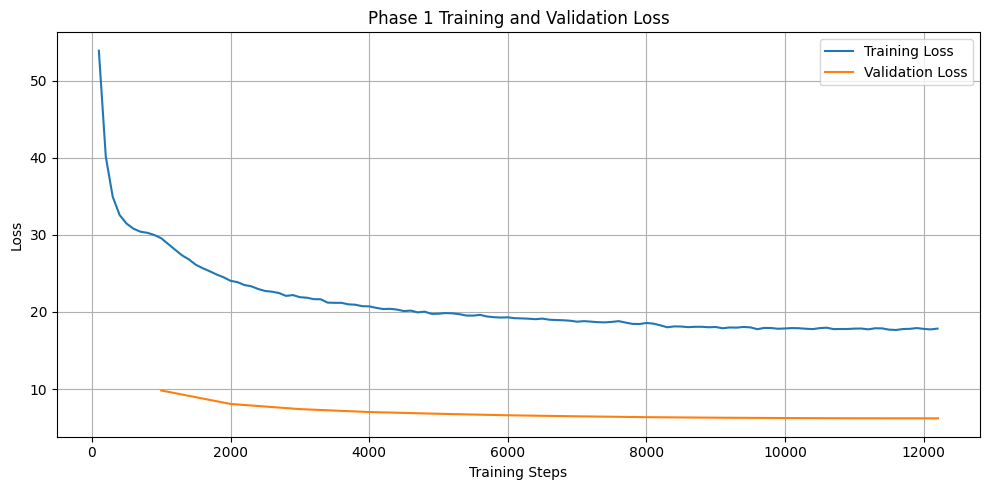

Loss plot saved to:
/kaggle/working/cs781_phase1/training_validation_loss.png


In [15]:
import matplotlib.pyplot as plt

logs = trainer.state.log_history

train_steps = []
train_loss = []
eval_steps = []
eval_loss = []

for log in logs:
    if ("loss" in log and "step" in log):
        train_steps.append(log["step"])
        train_loss.append(log["loss"])
    if ("eval_loss" in log and "step" in log):
        eval_steps.append(log["step"])
        eval_loss.append(log["eval_loss"])

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_loss, label="Training Loss")
plt.plot(eval_steps, eval_loss, label="Validation Loss")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Phase 1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print("Loss plot saved to:")
print(LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [17]:
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

FINAL_STATE_PATH = os.path.join(
    MODEL_OUTPUT_DIR,
    "ssm_state_dict.pt"
)

torch.save(ssm_model.state_dict(), FINAL_STATE_PATH)

print("Final model state_dict saved to:")
print(FINAL_STATE_PATH)


Final model state_dict saved to:
/kaggle/working/cs781_phase1/legal-mamba-ssm-final/ssm_state_dict.pt


## 15. Push Model to Hugging Face Hub

In [ ]:
# model.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)
# tokenizer.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)

# print("Model and tokenizer pushed successfully.")

## 16. Load Test Data from HuggingFace

In [18]:
from huggingface_hub import hf_hub_download
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Test file:", test_file_path)

test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [19]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))

Number of test examples: 1000


## 18. Load Final Model for Generation

In [39]:
import torch

generation_tokenizer = tokenizer

# Recreate the exact same architecture values used during training.
generation_model = SSMLM(
    vocab_size=tokenizer.vocab_size,
    dim=N_EMBD,
    n_layer=N_LAYER,
    max_seq_len=MODEL_CONTEXT_LENGTH,
    state_dim=SSM_STATE_DIM,
    expand=SSM_EXPAND,
)

FINAL_STATE_PATH = os.path.join(
    MODEL_OUTPUT_DIR,
    "ssm_state_dict.pt"
)

generation_model.load_state_dict(
    torch.load(FINAL_STATE_PATH, map_location="cpu")
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
generation_model = generation_model.to(device)
generation_model.eval()

print("Device:", device)
print(f"Parameters: {sum(p.numel() for p in generation_model.parameters()) / 1e6:.2f}M")


Device: cuda
Parameters: 67.28M


## 19. Generate 128 Words
#### (words, not tokens)

In [49]:
def sample_next_token(logits, temperature=1.0, top_p=0.95):
    """Sampling helper used by the manual autoregressive loop."""

    logits = logits / max(temperature, 1e-6)
    probs = torch.softmax(logits, dim=-1)

    sorted_probs, sorted_idx = torch.sort(probs, descending=True)
    cumulative = torch.cumsum(sorted_probs, dim=-1)

    remove = cumulative > top_p
    remove[..., 1:] = remove[..., :-1].clone()
    remove[..., 0] = False

    sorted_probs = sorted_probs.masked_fill(remove, 0.0)
    sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)

    sampled_pos = torch.multinomial(sorted_probs, num_samples=1)
    return sorted_idx.gather(-1, sampled_pos)


def generate_one(
    prompt,
    model,
    tokenizer,
    device,
    target_words=128,
    max_new_tokens=MAX_GENERATION_TOKENS,
    temperature=TEMPERATURE,
    top_p=TOP_P,
    repetition_penalty=1.0,   # choose/test this yourself
):
    ids = tokenizer.encode(prompt)

    # CHANGE 1:
    # Keep the full available prompt.
    # No need to reserve max_new_tokens positions.
    ids = ids[-MODEL_CONTEXT_LENGTH:]

    generated = list(ids)
    continuation = []

    model.eval()

    with torch.inference_mode():

        for _ in range(max_new_tokens):

            # Sliding context window
            context = generated[-MODEL_CONTEXT_LENGTH:]

            input_ids = torch.tensor(
                [context],
                dtype=torch.long,
                device=device
            )

            outputs = model(input_ids=input_ids)

            # CHANGE 2:
            next_logits = outputs["logits"][:, -1, :].clone()

            # Never generate padding
            next_logits[:, PAD_ID] = float("-inf")

            # CHANGE 3:
            # Optional repetition penalty
            if repetition_penalty != 1.0 and len(continuation) > 0:

                previous = torch.tensor(
                    list(set(continuation)),
                    dtype=torch.long,
                    device=device
                )

                old = next_logits[0, previous]

                next_logits[0, previous] = torch.where(
                    old < 0,
                    old * repetition_penalty,
                    old / repetition_penalty
                )

            # Current continuation
            text = tokenizer.decode(continuation)
            current_words = len(text.split())

            # CHANGE 4:
            # Don't allow EOS before getting 128 words
            if current_words < target_words:
                next_logits[:, EOS_ID] = float("-inf")

            next_id = sample_next_token(
                next_logits,
                temperature=temperature,
                top_p=top_p
            ).item()

            generated.append(next_id)
            continuation.append(next_id)

            text = tokenizer.decode(continuation)

            # Stop once we have enough words
            if len(text.split()) >= target_words:
                return " ".join(
                    text.split()[:target_words]
                )

    text = tokenizer.decode(continuation)

    if len(text.split()) < target_words:
        raise RuntimeError(
            f"Generated only {len(text.split())} words "
            f"after {max_new_tokens} tokens."
        )

    return " ".join(text.split()[:target_words])


def generate_batch(prompts, model, tokenizer, device, target_words=128):
    # Simple no-padding version first. Once the architecture works,
    # you can optimize generation throughput separately.
    return [
        generate_one(
            prompt=p,
            model=model,
            tokenizer=tokenizer,
            device=device,
            target_words=target_words,
        )
        for p in prompts
    ]


In [28]:
import math
import torch
from torch.utils.data import DataLoader

loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    collate_fn=data_collator
)

generation_model.eval()

total_loss = 0.0
total_tokens = 0

with torch.inference_mode():

    for batch in loader:

        input_ids = batch["input_ids"].to(device)
        labels = batch["labels"].to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):

            out = generation_model(
                input_ids=input_ids,
                labels=labels
            )

        # One next-token target is ignored per sequence
        valid_tokens = (
            input_ids.shape[0]
            * (input_ids.shape[1] - 1)
        )

        total_loss += (
            out["loss"].item()
            * valid_tokens
        )

        total_tokens += valid_tokens


final_loss = total_loss / total_tokens
final_ppl = math.exp(final_loss)

print("Final validation loss:", final_loss)
print("Final perplexity:", final_ppl)

Final validation loss: 3.1015872102641318
Final perplexity: 22.233212073301093


## 20. Generate Predictions for the Test Set

In [34]:
# Select one actual test prompt
example_id = list(test_data.keys())[99]
test_prompt = test_data[example_id]["text"]

generated_text = generate_one(
    prompt=test_prompt,
    model=generation_model,
    tokenizer=generation_tokenizer,
    device=device,
    target_words=128,
)

print("Generated text:")
print(repr(generated_text))
print("Generated words:", len(generated_text.split()))


Generated text:
'of the fact that the reservation of seats in the Backward Classes is to be filled by the Select List for the year in the office of the District Council, the appellant would be a candidate for appointment as a member of the Service from the District Judge. In this case, the High Court was not within the purview of the aforesaid amendment by the Constitution (Ninetal Areas and Panchayats Act. The said petition was registered by the High Court of Rajasthan and it was not the case of the petitioners-petitioners. In view of the factual position that the provisions of Section 17 of the Act were violated, the provisions of the Act relating to limitation under Section 11(6) of the Act and those made thereunder, the provisions'
Generated words: 128


In [24]:
print("Tokenizer vocab:", len(tokenizer.itos))
print("Model vocab:", generation_model.vocab_size)
print("PAD:", PAD_ID)
print("EOS:", EOS_ID)


Tokenizer vocab: 16000
Model vocab: 16000
PAD: 0
EOS: 3


In [51]:
# Resumable: re-running this cell continues after the last saved example.
if "predictions" not in globals():
    predictions = {}

import json

items = list(test_data.items())
total_examples = len(items)

start_from = len(predictions)

print("Already completed:", start_from)
print("Total examples:", total_examples)

SAVE_PATH = "/kaggle/working/predictions_partial.json"

for idx in range(start_from, total_examples):

    example_id, record = items[idx]
    prompt = record["text"]

    try:
        prediction = generate_one(
            prompt=prompt,
            model=generation_model,
            tokenizer=generation_tokenizer,
            device=device,
            target_words=128,
            max_new_tokens=700
        )

    except RuntimeError:
        # Rare case: 700 tokens were still not enough
        print(f"Retrying example {idx} with 1200 tokens...")

        prediction = generate_one(
            prompt=prompt,
            model=generation_model,
            tokenizer=generation_tokenizer,
            device=device,
            target_words=128,
            max_new_tokens=1200
        )

    predictions[str(example_id)] = {
        "text": prediction
    }

    # Save immediately, so progress is never lost
    with open(
        SAVE_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            predictions,
            f,
            ensure_ascii=False,
            indent=2
        )

    completed = idx + 1

    print(
        f"Completed {completed}/{total_examples} "
        f"({100 * completed / total_examples:.1f}%)"
    )

print("Final prediction count:", len(predictions))
print("Saved to:", SAVE_PATH)

Already completed: 0
Total examples: 1000
Completed 1/1000 (0.1%)
Completed 2/1000 (0.2%)
Completed 3/1000 (0.3%)
Completed 4/1000 (0.4%)
Completed 5/1000 (0.5%)
Completed 6/1000 (0.6%)
Completed 7/1000 (0.7%)
Completed 8/1000 (0.8%)
Completed 9/1000 (0.9%)
Completed 10/1000 (1.0%)
Completed 11/1000 (1.1%)
Completed 12/1000 (1.2%)
Completed 13/1000 (1.3%)
Completed 14/1000 (1.4%)
Completed 15/1000 (1.5%)
Completed 16/1000 (1.6%)
Completed 17/1000 (1.7%)
Completed 18/1000 (1.8%)
Completed 19/1000 (1.9%)
Completed 20/1000 (2.0%)
Completed 21/1000 (2.1%)
Completed 22/1000 (2.2%)
Completed 23/1000 (2.3%)
Completed 24/1000 (2.4%)
Completed 25/1000 (2.5%)
Completed 26/1000 (2.6%)
Completed 27/1000 (2.7%)
Completed 28/1000 (2.8%)
Completed 29/1000 (2.9%)
Completed 30/1000 (3.0%)
Completed 31/1000 (3.1%)
Completed 32/1000 (3.2%)
Completed 33/1000 (3.3%)
Completed 34/1000 (3.4%)
Completed 35/1000 (3.5%)
Completed 36/1000 (3.6%)
Completed 37/1000 (3.7%)
Completed 38/1000 (3.8%)
Completed 39/1000

## 21. Save prediction.json

In [52]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(
        predictions,
        f,
        ensure_ascii=False,
        indent=2
    )

print("prediction.json saved:")
print(PREDICTION_PATH)

prediction.json saved:
/kaggle/working/cs781_phase1/prediction.json


## 22. Create CodaBench Submission ZIP

In [54]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:")
print(SUBMISSION_ZIP)

Codabench submission created:
/kaggle/working/cs781_phase1/submission.zip
